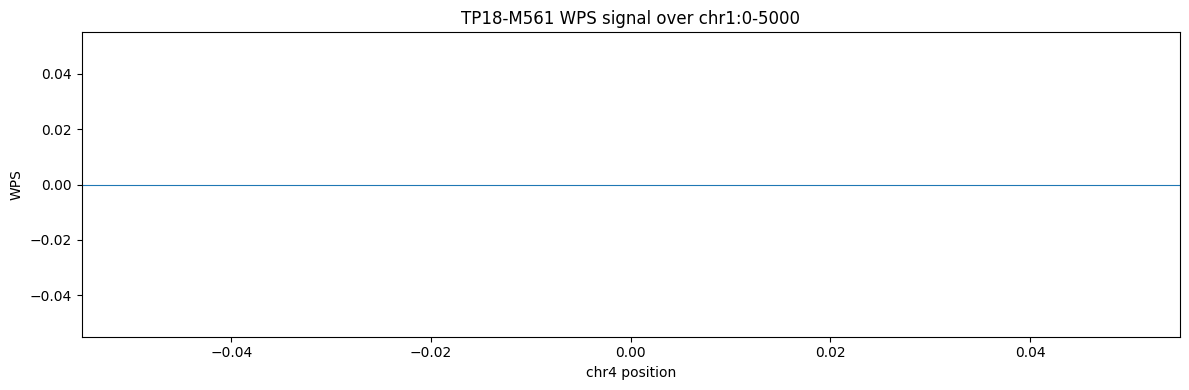

In [7]:
# Window Protected Score based on Snyder et al. 2016., by using FinaleTool for test run
import pyBigWig
import numpy as np
import matplotlib.pyplot as plt

bw_path = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Finale/wps_test/TP18-M561.allchr.5kb_windows.wps.bw"
chrom = "chr4"
start = 0
end = 5000

bw = pyBigWig.open(bw_path)
vals = np.array(bw.values(chrom, start, end, numpy=True), dtype=float)
bw.close()

x = np.arange(start, end)

plt.figure(figsize=(12, 4))
plt.plot(x, vals, linewidth=1)
plt.axhline(0, linewidth=0.8)
plt.xlabel(f"{chrom} position")
plt.ylabel("WPS")
plt.title("TP18-M561 WPS signal over chr1:0-5000")
plt.tight_layout()
plt.show()

In [8]:
import os
import pyBigWig
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# INPUT / OUTPUT
# ============================================================
bw_path = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Finale/wps_test/TP18-M561.allchr.5kb_windows.wps.bw"
outdir = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Finale/wps_test/WPS_plots_all_chr"
os.makedirs(outdir, exist_ok=True)

# Number of bins used to summarize each chromosome
# increase for more detail, decrease for faster plotting
n_bins_per_chr = 2000

# Keep only standard chromosomes if needed
primary_only = True

# ============================================================
# HELPERS
# ============================================================
def is_primary_chr(chrom):
    primary = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY", "chrM"]
    return chrom in primary

# ============================================================
# LOAD BIGWIG
# ============================================================
if not os.path.exists(bw_path):
    raise FileNotFoundError(f"bigWig file not found: {bw_path}")

bw = pyBigWig.open(bw_path)
chrom_sizes = bw.chroms()

# chromosome order
chrom_order = list(chrom_sizes.keys())
if primary_only:
    chrom_order = [c for c in chrom_order if is_primary_chr(c)]

if len(chrom_order) == 0:
    bw.close()
    raise ValueError("No chromosomes found to plot.")

print("Chromosomes to plot:")
print(chrom_order)

# ============================================================
# 1. PLOT EACH CHROMOSOME ACROSS FULL LENGTH
# ============================================================
for chrom in chrom_order:
    chrom_len = chrom_sizes[chrom]

    # summarize chromosome into bins
    vals = bw.stats(chrom, 0, chrom_len, nBins=n_bins_per_chr, exact=True)
    vals = np.array([0 if v is None else v for v in vals], dtype=float)

    x = np.linspace(0, chrom_len, num=len(vals))

    plt.figure(figsize=(14, 4))
    plt.plot(x, vals, linewidth=1)
    plt.axhline(0, linewidth=0.8)

    plt.xlabel(f"{chrom} position (bp)")
    plt.ylabel("Mean WPS")
    plt.title(f"TP18-M561 WPS across full {chrom}")

    plt.tight_layout()
    plt.savefig(os.path.join(outdir, f"TP18-M561_{chrom}_WPS_full.png"), dpi=300, bbox_inches="tight")
    plt.savefig(os.path.join(outdir, f"TP18-M561_{chrom}_WPS_full.pdf"), bbox_inches="tight")
    plt.close()

# ============================================================
# 2. COMBINED GENOME-WIDE PLOT
# ============================================================
all_x = []
all_y = []
tick_positions = []
tick_labels = []

offset = 0

for chrom in chrom_order:
    chrom_len = chrom_sizes[chrom]

    vals = bw.stats(chrom, 0, chrom_len, nBins=n_bins_per_chr, exact=True)
    vals = np.array([0 if v is None else v for v in vals], dtype=float)

    x = np.linspace(offset, offset + chrom_len, num=len(vals))

    all_x.append(x)
    all_y.append(vals)

    tick_positions.append(offset + chrom_len / 2)
    tick_labels.append(chrom)

    offset += chrom_len

bw.close()

all_x = np.concatenate(all_x)
all_y = np.concatenate(all_y)

plt.figure(figsize=(20, 5))
plt.plot(all_x, all_y, linewidth=0.8)
plt.axhline(0, linewidth=0.8)

# chromosome boundaries
offset = 0
for chrom in chrom_order[:-1]:
    offset += chrom_sizes[chrom]
    plt.axvline(offset, linewidth=0.5)

plt.xticks(tick_positions, tick_labels, rotation=90)
plt.xlabel("Genome position")
plt.ylabel("Mean WPS")
plt.title("TP18-M561 genome-wide WPS across all chromosomes")

plt.tight_layout()
plt.savefig(os.path.join(outdir, "TP18-M561_genomewide_WPS.png"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(outdir, "TP18-M561_genomewide_WPS.pdf"), bbox_inches="tight")
plt.close()

print(f"Plots saved in: {outdir}")

Chromosomes to plot:
['chr1', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr20', 'chr21', 'chr22', 'chrX', 'chrY', 'chrM']
Plots saved in: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Finale/wps_test/WPS_plots_all_chr
